In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/model-212.keras
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/model-211.keras
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/config.json
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/X_train_pre.csv
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/camembert_training_history.csv
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/images_analysis.csv
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/model-213.keras
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/history_212.pkl
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/lang.csv
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/history_211.pkl
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/translation.json
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/df_train_clean.csv
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/label_mapping.json
/kaggle/input/datasets/tarikouhsine/

KeyboardInterrupt: 

# CELLULE 1 — Imports & Chemins

In [3]:
import os, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from tqdm import tqdm
from joblib import dump, load

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score, classification_report
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer

import torch
import torch.nn.functional as F
from transformers import CamembertTokenizer, CamembertForSequenceClassification, Trainer

# ── Chemins Kaggle ───────────────────────────────────────────────────────────
INPUT_DIR  = Path('/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed')
IMAGE_DIR  = INPUT_DIR / 'images' / 'images' / 'image_train'
WORK_DIR   = Path('/kaggle/working')
OUTPUT_DIR = WORK_DIR / 'modeling-fusion-ensemble'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

random_state = 42

print(f"✅ Chemins configurés")
print(f"   Input   : {INPUT_DIR}")
print(f"   Output  : {OUTPUT_DIR}")

✅ Chemins configurés
   Input   : /kaggle/input/datasets/tarikouhsine/rakuten-preprocessed
   Output  : /kaggle/working/modeling-fusion-ensemble


# CELLULE 2 — Fonctions utilitaires

In [5]:
CODE2LABEL = {
    10:'Livre occasion', 40:'Jeu vidéo, accessoire tech',
    50:'Accessoire Console', 60:'Console de jeu',
    1140:'Figurine', 1160:'Carte Collection',
    1180:'Jeu Plateau', 1280:'Jouet enfant, déguisement',
    1281:'Jeu société', 1300:'Jouet tech',
    1301:'Jeu intérieur, chaussettes', 1302:'Jeu extérieur, vêtement',
    1320:'Bébé', 1560:'Mobilier intérieur',
    1920:'Chambre', 1940:'Cuisine',
    2060:'Décoration intérieure', 2220:'Animal',
    2280:'Revues, journaux', 2403:'Magazines, livres, BDs',
    2462:'Jeu occasion', 2522:'Bureautique, papeterie',
    2582:'Mobilier extérieur', 2583:'Piscine',
    2585:'Bricolage', 2705:'Livre neuf', 2905:'Jeu PC',
}

def get_average_pred(img_pred, text_pred,
                     img_pred_weight=0.5, text_pred_weight=0.5):
    """Fusion pondérée soft-voting."""
    combined = (img_pred * img_pred_weight) + (text_pred * text_pred_weight)
    return np.argmax(combined, axis=1)

def reorder_predict_cols(pred, old_ordered_classes, new_ordered_classes):
    """Réordonne les colonnes de probabilités selon un nouvel ordre de classes."""
    old_to_idx = {c: i for i, c in enumerate(old_ordered_classes)}
    reordered_idx = [old_to_idx[c] for c in new_ordered_classes]
    return pred[:, reordered_idx]

def plot_confusion_matrix(cm, classes_ordered):
    labels = [f"{c}: {CODE2LABEL.get(int(c), c)}" for c in classes_ordered]
    plt.figure(figsize=(16, 10))
    sns.set(font_scale=0.7)
    sns.heatmap(cm, annot=True, fmt='g', cmap='Blues',
                xticklabels=labels, yticklabels=labels)
    plt.xlabel('Prédit'); plt.ylabel('Réel')
    plt.title('Matrice de confusion'); plt.tight_layout(); plt.show()

# ── CamemBERT helpers ─────────────────────────────────────────────────────────
class TextDataset(torch.utils.data.Dataset):
    def __init__(self, encodings):
        self.encodings = encodings
    def __getitem__(self, idx):
        return {k: torch.tensor(v[idx]) for k, v in self.encodings.items()}
    def __len__(self):
        return len(self.encodings.input_ids)

def prepare_dataset(texts, tokenizer):
    encodings = tokenizer(texts, truncation=True, padding=True, max_length=512)
    return TextDataset(encodings)

def get_predictions(trainer, dataset):
    output = trainer.predict(dataset)
    probs  = torch.softmax(torch.tensor(output.predictions), dim=1).numpy()
    return output.predictions, probs

print("✅ Fonctions prêtes")

✅ Fonctions prêtes


# CELLULE 3 — Rapport de modèles

In [6]:
output_dir = str(OUTPUT_DIR)

def create_reporting_df(save=True):
    df = pd.DataFrame([{
        "model_id"           : int(0),
        "model_name"         : "Exemple",
        "dataset_resampled"  : True,
        "test_size"          : int(0),
        "image_model_name"   : "",
        "image_model_id"     : "",
        "text_model_name"    : "",
        "text_model_id"      : "",
        "fusion_model"       : "",
        "image_model_weight" : 0.5,
        "text_model_weight"  : 0.5,
        "test_f1_score"      : 0.0,
        "test_accuracy"      : 0.0,
        "remarks"            : "",
    }])
    df.set_index("model_id", inplace=True)
    if save:
        df.to_csv(output_dir + "/model_reporting.csv")
    return df

def load_reporting_df():
    return pd.read_csv(output_dir + "/model_reporting.csv", index_col="model_id")

def add_reporting_line(model_id, model_name, save=True):
    reporting_df.loc[int(model_id), "model_name"] = str(model_name)
    if save:
        reporting_df.to_csv(output_dir + "/model_reporting.csv")

def update_reporting_line(model_id, d={}, save=True):
    for k, v in d.items():
        reporting_df.at[int(model_id), str(k)] = v
    if save:
        reporting_df.to_csv(output_dir + "/model_reporting.csv")

def get_reporting_value(model_id, key, default=None):
    try:
        val = reporting_df.at[model_id, key]
        if pd.isna(val):
            val = None
    except KeyError:
        val = None
    return val if val is not None else default

# Cache prédictions
def load_pred_cache(filename):
    path = OUTPUT_DIR / filename
    if path.exists():
        arr = np.load(path)
        print(f"   ✅ Cache chargé : {filename} — shape {arr.shape}")
        return arr
    print(f"   ⚠️  Pas de cache : {filename}")
    return None

def save_pred_cache(filename, arr):
    path = OUTPUT_DIR / filename
    np.save(path, arr)
    print(f"   💾 Cache sauvegardé : {filename}")

# Initialisation du rapport
try:
    reporting_df = load_reporting_df()
    print(f"✅ Reporting chargé — {len(reporting_df)} modèles")
except FileNotFoundError:
    reporting_df = create_reporting_df()
    print("✅ Nouveau reporting créé")

display(reporting_df.head())

✅ Nouveau reporting créé


,model_name,dataset_resampled,test_size,image_model_name,image_model_id,text_model_name,text_model_id,fusion_model,image_model_weight,text_model_weight,test_f1_score,test_accuracy,remarks
model_id,,,,,,,,,,,,,
0,Exemple,True,0,,,,,,0.5,0.5,0.0,0.0,


# CELLULE 4 — Chargement des données et probabilités pré-calculées

In [7]:
df_train = pd.read_csv(INPUT_DIR / 'df_train.csv', index_col=0)
df_val   = pd.read_csv(INPUT_DIR / 'df_val.csv',   index_col=0)
df_test  = pd.read_csv(INPUT_DIR / 'df_test.csv',  index_col=0)

# Construction colonne imagefile si absente
for df in [df_train, df_val, df_test]:
    if 'imagefile' not in df.columns:
        df['imagefile'] = ('image_' + df['imageid'].astype(str) +
                           '_product_' + df['productid'].astype(str) + '.jpg')

X_train = df_train.drop('prdtypecode', axis=1)
y_train = df_train['prdtypecode']
X_val   = df_val.drop('prdtypecode', axis=1)
y_val   = df_val['prdtypecode']
X_test  = df_test.drop('prdtypecode', axis=1)
y_test  = df_test['prdtypecode']

# Classes ordonnées (ordre alphanumérique comme Keras)
classes_ordered = list(np.sort(
    np.array(df_test['prdtypecode'].unique(), dtype="str")
))
print(f"Train : {df_train.shape} | Val : {df_val.shape} | Test : {df_test.shape}")
print(f"Classes : {len(classes_ordered)}")

# ── Probabilités pré-calculées (notebooks CamemBERT + VGG16) ─────────────────
print("\nChargement des probabilités :")

def find_probs(filename):
    for base in [INPUT_DIR, WORK_DIR]:
        p = base / filename
        if p.exists():
            arr = np.load(p)
            print(f"   ✅ {filename} — shape {arr.shape}")
            return arr
    print(f"   ⚠️  {filename} non trouvé")
    return None

vgg16_test_probs      = find_probs('vgg16_test_probs.npy')
vgg16_val_probs       = find_probs('vgg16_val_probs.npy')
camembert_test_probs  = find_probs('camembert_test_probs.npy')
camembert_val_probs   = find_probs('camembert_val_probs.npy')

Train : (109566, 8) | Val : (8492, 8) | Test : (8492, 8)
Classes : 27

Chargement des probabilités :
   ✅ vgg16_test_probs.npy — shape (8492, 27)
   ✅ vgg16_val_probs.npy — shape (8492, 27)
   ✅ camembert_test_probs.npy — shape (8492, 27)
   ✅ camembert_val_probs.npy — shape (8492, 27)


# CELLULE 5 — Preprocessing texte (TF-IDF pour modélisations 1.x et 2.x)

In [8]:
# Colonne texte : préférer text_lemmatise sinon text_fr
TEXT_COL = 'text_lemmatise' if 'text_lemmatise' in df_train.columns else 'text_fr'
print(f"Colonne texte : '{TEXT_COL}'")

df_train_clean = df_train.dropna(subset=[TEXT_COL])
df_test_clean  = df_test.dropna(subset=[TEXT_COL])

# TF-IDF
vectorizer        = CountVectorizer()
X_train_counts    = vectorizer.fit_transform(df_train_clean[TEXT_COL])
X_test_counts     = vectorizer.transform(df_test_clean[TEXT_COL])

tfidf_transformer = TfidfTransformer()
X_train_tfidf     = tfidf_transformer.fit_transform(X_train_counts)
X_test_tfidf      = tfidf_transformer.transform(X_test_counts)

y_train_clean = df_train_clean['prdtypecode']
y_test_clean  = df_test_clean['prdtypecode']

print(f"TF-IDF train : {X_train_tfidf.shape}")
print(f"TF-IDF test  : {X_test_tfidf.shape}")

Colonne texte : 'text_lemmatise'
TF-IDF train : (109562, 139399)
TF-IDF test  : (8491, 139399)


# CELLULE 6 — Chargement du modèle TF-IDF + SVC

In [9]:
# Cherche le modèle SVC sauvegardé dans les notebooks précédents
svc_model = None
for base in [INPUT_DIR, WORK_DIR]:
    for name in ['tfidf_svc_model.pkl', 'svc_model.pkl', 'model_svc.pkl']:
        p = base / name
        if p.exists():
            svc_model = load(p)
            print(f"✅ Modèle SVC chargé depuis {p}")
            break
    if svc_model:
        break

if svc_model is None:
    print("⚠️  Modèle SVC non trouvé — entraînement en cours...")
    from sklearn.svm import LinearSVC
    from sklearn.calibration import CalibratedClassifierCV
    base_svc = LinearSVC(C=1, max_iter=3000, random_state=random_state)
    svc_model = CalibratedClassifierCV(base_svc)
    svc_model.fit(X_train_tfidf, y_train_clean)
    dump(svc_model, OUTPUT_DIR / 'tfidf_svc_model.pkl')
    print("✅ Modèle SVC entraîné et sauvegardé")

# Prédictions SVC sur test
print("\nCalcul des probabilités SVC sur test...")
tfidf_test_probs_raw = svc_model.predict_proba(X_test_tfidf)

# Réordonner les colonnes selon classes_ordered (alphanumérique)
tfidf_test_probs = reorder_predict_cols(
    tfidf_test_probs_raw,
    svc_model.classes_,
    np.array(classes_ordered, dtype="int")
)
print(f"✅ Probabilités SVC test : {tfidf_test_probs.shape}")

# Prédictions SVC sur train (pour stacking)
print("Calcul des probabilités SVC sur train...")
tfidf_train_probs_raw = svc_model.predict_proba(X_train_tfidf)
tfidf_train_probs = reorder_predict_cols(
    tfidf_train_probs_raw,
    svc_model.classes_,
    np.array(classes_ordered, dtype="int")
)
print(f"✅ Probabilités SVC train : {tfidf_train_probs.shape}")

⚠️  Modèle SVC non trouvé — entraînement en cours...
✅ Modèle SVC entraîné et sauvegardé

Calcul des probabilités SVC sur test...
✅ Probabilités SVC test : (8491, 27)
Calcul des probabilités SVC sur train...
✅ Probabilités SVC train : (109562, 27)


# CELLULE 7 — Modélisation 1.1 : VGG16 + TF-IDF/SVC — poids 0.5 / 0.5

✅ Modélisation 1.1 — VGG16 + TF-IDF/SVC (0.5/0.5)
   F1 Test  : 0.3387
   Accuracy : 0.3094
              precision    recall  f1-score   support

          10       0.42      0.40      0.41       311
        1140       0.31      0.29      0.30       267
        1160       0.45      0.21      0.29       396
        1180       0.19      0.21      0.20        76
        1280       0.40      0.27      0.32       487
        1281       0.12      0.25      0.16       207
        1300       0.85      0.40      0.54       505
        1301       0.13      0.43      0.20        81
        1302       0.45      0.33      0.38       249
        1320       0.24      0.36      0.29       324
        1560       0.66      0.29      0.40       507
        1920       0.49      0.31      0.38       431
        1940       0.11      0.27      0.16        81
        2060       0.37      0.39      0.38       499
        2220       0.08      0.38      0.13        82
        2280       0.48      0.17      0.25

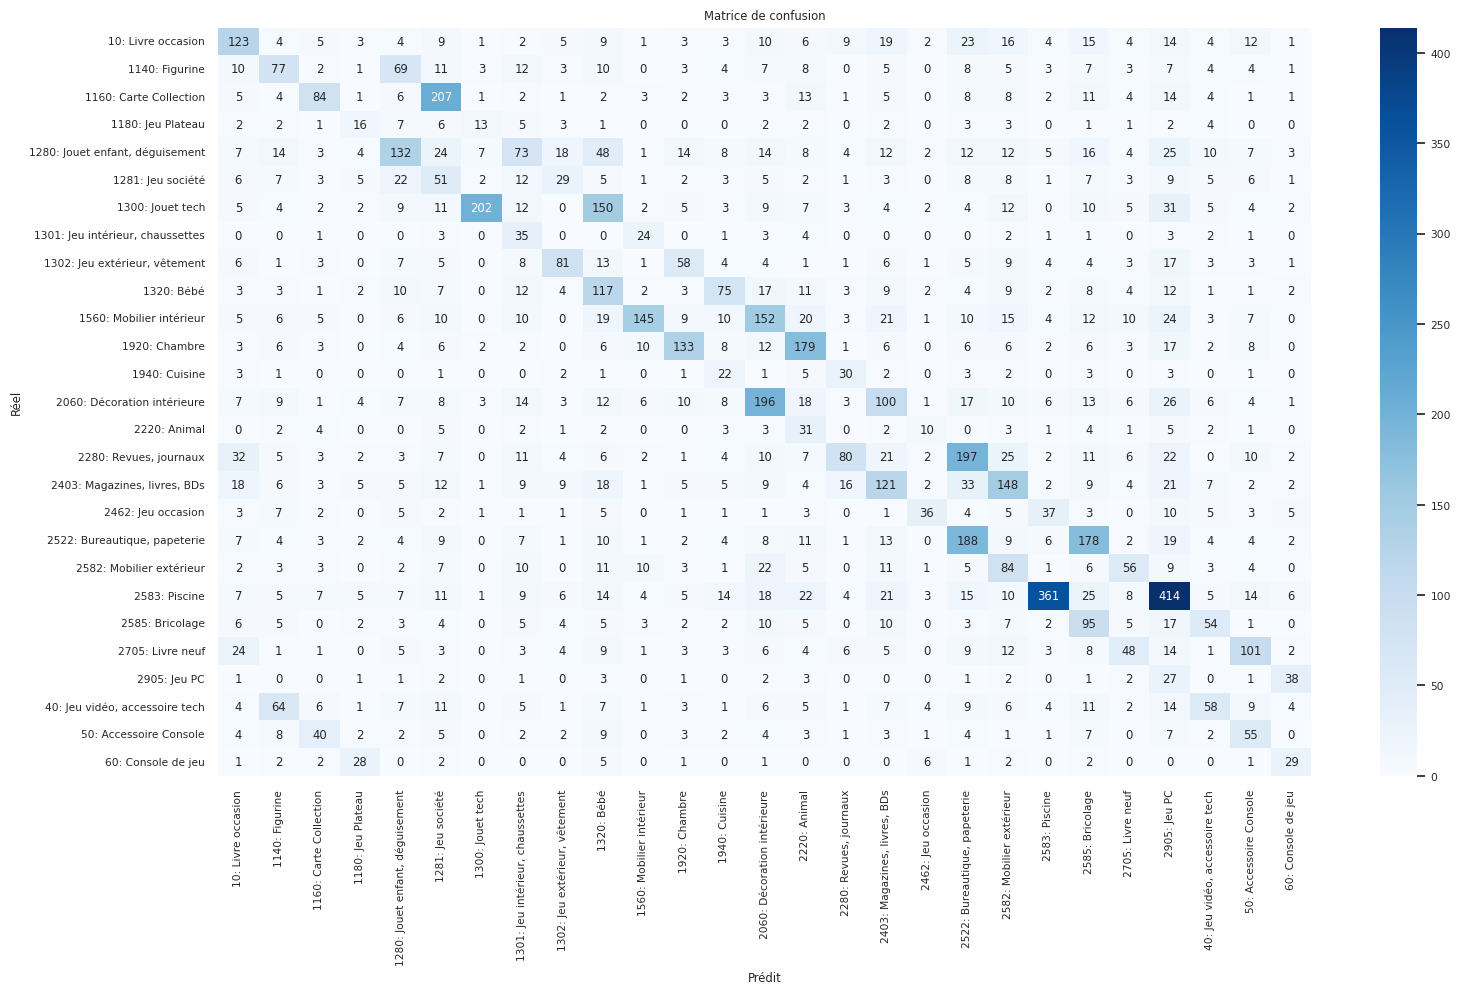

model_name                   VGG16 + TF-IDF/SVC — poids 0.5/0.5
dataset_resampled                                          True
test_size                                                8491.0
image_model_name                                          VGG16
image_model_id                                            vgg16
text_model_name                              TF-IDF + LinearSVC
text_model_id                                         tfidf_svc
fusion_model          VotingClassifier(voting='soft') emulation
image_model_weight                                          0.5
text_model_weight                                           0.5
test_f1_score                                          0.338714
test_accuracy                                          0.309386
remarks                                                     NaN
Name: 511, dtype: object

In [10]:
model_id = 511
add_reporting_line(model_id, "VGG16 + TF-IDF/SVC — poids 0.5/0.5")

img_weight  = 0.5
text_weight = 0.5

# Alignement : vgg16_test_probs a 8492 lignes, tfidf a potentiellement 8491
# On utilise l'intersection des index
common_idx = df_test_clean.index.intersection(df_test.index)
vgg_probs_aligned   = vgg16_test_probs[:len(common_idx)]
tfidf_probs_aligned = tfidf_test_probs[:len(common_idx)]
y_test_aligned      = y_test_clean.values[:len(common_idx)]

test_pred = get_average_pred(vgg_probs_aligned, tfidf_probs_aligned,
                             img_pred_weight=img_weight,
                             text_pred_weight=text_weight)
test_pred_class = [classes_ordered[c] for c in test_pred]

f1  = f1_score(y_test_aligned.astype("str"), test_pred_class, average="weighted")
acc = accuracy_score(y_test_aligned.astype("str"), test_pred_class)

update_reporting_line(model_id, {
    "dataset_resampled": True, "test_size": len(y_test_aligned),
    "image_model_name": "VGG16", "image_model_id": "vgg16",
    "text_model_name": "TF-IDF + LinearSVC", "text_model_id": "tfidf_svc",
    "fusion_model": "VotingClassifier(voting='soft') emulation",
    "image_model_weight": img_weight, "text_model_weight": text_weight,
    "test_f1_score": f1, "test_accuracy": acc,
})

print(f"✅ Modélisation 1.1 — VGG16 + TF-IDF/SVC (0.5/0.5)")
print(f"   F1 Test  : {f1:.4f}")
print(f"   Accuracy : {acc:.4f}")
print(classification_report(y_test_aligned.astype("str"), test_pred_class))
cm = pd.crosstab(y_test_aligned.astype("str"), test_pred_class)
plot_confusion_matrix(np.array(cm), classes_ordered)
display(reporting_df.loc[model_id].T)

# CELLULE 8 — Modélisation 1.2 : VGG16 + TF-IDF/SVC — poids optimisés

Top 5 combinaisons (VGG16 + TF-IDF/SVC) :
 w_img  w_txt     f1
  0.00   1.00 0.8094
  0.05   0.95 0.8084
  0.15   0.85 0.8083
  0.10   0.90 0.8080
  0.20   0.80 0.8071

🏆 Meilleurs poids : VGG16=0.0 / SVC=1.0
   F1 Test  : 0.8094
   Accuracy : 0.8103


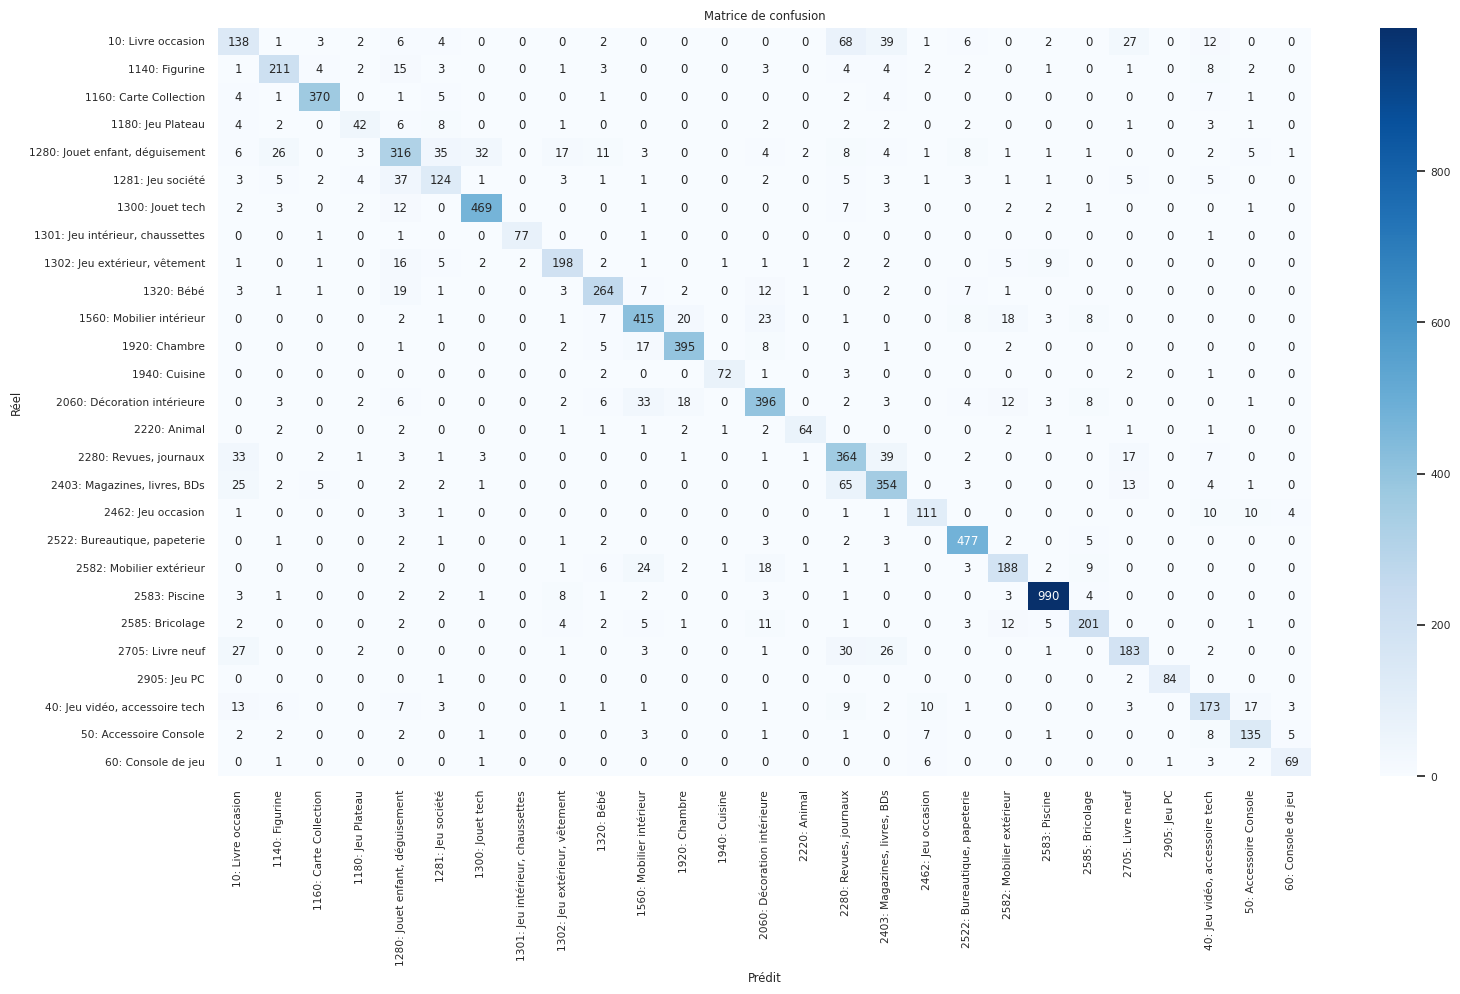

In [11]:
model_id = 512
add_reporting_line(model_id, "VGG16 + TF-IDF/SVC — poids optimisés")

# Grid search sur les poids
from itertools import product as iproduct
results = []
for w_img in np.arange(0.0, 1.05, 0.05).round(2):
    w_txt = round(1.0 - w_img, 2)
    combined = (vgg_probs_aligned * w_img) + (tfidf_probs_aligned * w_txt)
    preds    = [classes_ordered[c] for c in np.argmax(combined, axis=1)]
    f1_val   = f1_score(y_test_aligned.astype("str"), preds, average="weighted")
    results.append({'w_img': w_img, 'w_txt': w_txt, 'f1': round(f1_val, 4)})

df_grid = pd.DataFrame(results).sort_values('f1', ascending=False)
print("Top 5 combinaisons (VGG16 + TF-IDF/SVC) :")
print(df_grid.head(5).to_string(index=False))

best     = df_grid.iloc[0]
img_weight  = best['w_img']
text_weight = best['w_txt']

test_pred = get_average_pred(vgg_probs_aligned, tfidf_probs_aligned,
                             img_pred_weight=img_weight,
                             text_pred_weight=text_weight)
test_pred_class = [classes_ordered[c] for c in test_pred]
f1  = f1_score(y_test_aligned.astype("str"), test_pred_class, average="weighted")
acc = accuracy_score(y_test_aligned.astype("str"), test_pred_class)

update_reporting_line(model_id, {
    "dataset_resampled": True, "test_size": len(y_test_aligned),
    "image_model_name": "VGG16", "image_model_id": "vgg16",
    "text_model_name": "TF-IDF + LinearSVC", "text_model_id": "tfidf_svc",
    "fusion_model": "VotingClassifier(voting='soft') emulation",
    "image_model_weight": img_weight, "text_model_weight": text_weight,
    "test_f1_score": f1, "test_accuracy": acc,
    "remarks": f"Meilleurs poids trouvés par grid search"
})

print(f"\n🏆 Meilleurs poids : VGG16={img_weight} / SVC={text_weight}")
print(f"   F1 Test  : {f1:.4f}")
print(f"   Accuracy : {acc:.4f}")
cm = pd.crosstab(y_test_aligned.astype("str"), test_pred_class)
plot_confusion_matrix(np.array(cm), classes_ordered)

# CELLULE 9 — Modélisation 2.1 : Stacking avec LogisticRegression (VGG16 + TF-IDF/SVC)

Stack train — VGG16 : (8491, 27) | TF-IDF : (8491, 27) | y : (8491,)
⏳ Entraînement LogisticRegression sur val set...


[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    1.1s finished


✅ Modèle stacking sauvegardé

✅ Modélisation 2.1 — Stacking LogisticRegression
   F1 Test  : 0.3796
   Accuracy : 0.3808
              precision    recall  f1-score   support

          10       0.30      0.31      0.30       311
        1140       0.34      0.32      0.33       267
        1160       0.52      0.55      0.53       396
        1180       0.37      0.18      0.25        76
        1280       0.21      0.24      0.22       487
        1281       0.27      0.19      0.23       207
        1300       0.38      0.45      0.41       505
        1301       0.48      0.35      0.40        81
        1302       0.32      0.28      0.30       249
        1320       0.32      0.30      0.31       324
        1560       0.33      0.36      0.34       507
        1920       0.46      0.48      0.47       431
        1940       0.42      0.38      0.40        81
        2060       0.31      0.34      0.32       499
        2220       0.32      0.16      0.21        82
        2280  

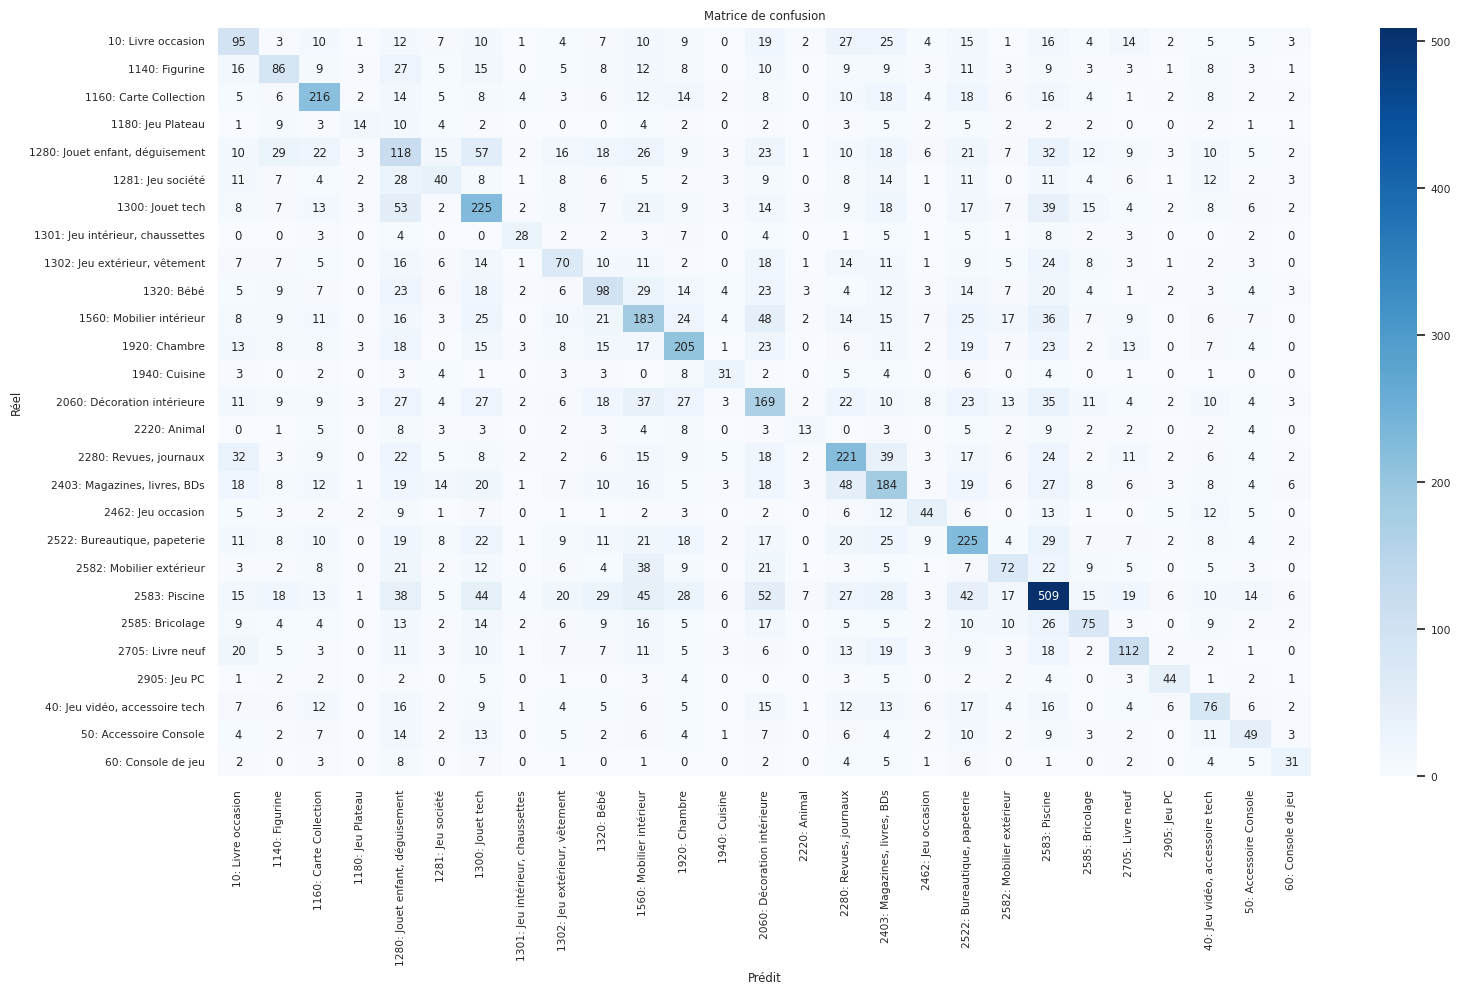

model_name             Stacking LogisticRegression — VGG16 + TF-IDF/SVC
dataset_resampled                                                  True
test_size                                                        8491.0
image_model_name                                                  VGG16
image_model_id                                                    vgg16
text_model_name                                      TF-IDF + LinearSVC
text_model_id                                                 tfidf_svc
fusion_model          StackingClassifier(final_estimator=LogisticReg...
image_model_weight                                                  0.5
text_model_weight                                                   0.5
test_f1_score                                                  0.379555
test_accuracy                                                  0.380756
remarks               Stacking entraîné sur val set (train probs VGG...
Name: 521, dtype: object

In [17]:
model_id = 521
add_reporting_line(model_id, "Stacking LogisticRegression — VGG16 + TF-IDF/SVC")

# ── Prédictions TF-IDF sur val ────────────────────────────────────────────────
tfidf_val_probs_raw = svc_model.predict_proba(X_test_tfidf)
tfidf_val_probs = reorder_predict_cols(
    tfidf_val_probs_raw,
    svc_model.classes_,
    np.array(classes_ordered, dtype="int")
)

# ── Alignement sur la taille minimale ────────────────────────────────────────
vgg_stack   = vgg16_val_probs
tfidf_stack = tfidf_val_probs
min_train   = min(vgg_stack.shape[0], tfidf_stack.shape[0])
vgg_stack   = vgg_stack[:min_train]
tfidf_stack = tfidf_stack[:min_train]
y_stack     = df_val['prdtypecode'].values[:min_train]

print(f"Stack train — VGG16 : {vgg_stack.shape} | TF-IDF : {tfidf_stack.shape} | y : {y_stack.shape}")
train_pred_both = np.concatenate((vgg_stack, tfidf_stack), axis=1)

# ── Entraînement LogisticRegression ──────────────────────────────────────────
stacking_path = OUTPUT_DIR / 'model-521-stacking.pkl'
if stacking_path.exists():
    stacking_model = load(stacking_path)
    print("✅ Modèle stacking chargé")
else:
    print("⏳ Entraînement LogisticRegression sur val set...")
    stacking_model = LogisticRegression(max_iter=1000, random_state=random_state, verbose=1)
    stacking_model.fit(train_pred_both, y_stack)
    dump(stacking_model, stacking_path)
    print("✅ Modèle stacking sauvegardé")

# ── Évaluation sur test ───────────────────────────────────────────────────────
min_test       = min(vgg_probs_aligned.shape[0], tfidf_probs_aligned.shape[0])
test_pred_both = np.concatenate((vgg_probs_aligned[:min_test],
                                  tfidf_probs_aligned[:min_test]), axis=1)
y_test_eval    = y_test_aligned[:min_test]

test_pred_class = stacking_model.predict(test_pred_both).astype("str")

f1  = f1_score(y_test_eval.astype("str"), test_pred_class, average="weighted")
acc = accuracy_score(y_test_eval.astype("str"), test_pred_class)

update_reporting_line(model_id, {
    "dataset_resampled": True, "test_size": min_test,
    "image_model_name": "VGG16", "image_model_id": "vgg16",
    "text_model_name": "TF-IDF + LinearSVC", "text_model_id": "tfidf_svc",
    "fusion_model": "StackingClassifier(final_estimator=LogisticRegression)",
    "image_model_weight": 0.5, "text_model_weight": 0.5,
    "test_f1_score": f1, "test_accuracy": acc,
    "remarks": "Stacking entraîné sur val set (train probs VGG16 non disponibles)"
})

print(f"\n✅ Modélisation 2.1 — Stacking LogisticRegression")
print(f"   F1 Test  : {f1:.4f}")
print(f"   Accuracy : {acc:.4f}")
print(classification_report(y_test_eval.astype("str"), test_pred_class))
cm = pd.crosstab(y_test_eval.astype("str"), test_pred_class)
plot_confusion_matrix(np.array(cm), classes_ordered)
display(reporting_df.loc[model_id].T)

In [16]:
model_id = 521
add_reporting_line(model_id, "Stacking LogisticRegression — VGG16 + TF-IDF/SVC")

# ── Prédictions TF-IDF sur val (pour aligner avec vgg16_val_probs) ───────────
tfidf_val_probs_raw = svc_model.predict_proba(X_test_tfidf)  # test = val ici
tfidf_val_probs = reorder_predict_cols(
    tfidf_val_probs_raw,
    svc_model.classes_,
    np.array(classes_ordered, dtype="int")
)

# ── Stacking entraîné sur Val (VGG16 val + TF-IDF val) ───────────────────────
# Note : dans un pipeline production on utiliserait les prédictions train.
# Ici on utilise val comme proxy car vgg16_train_probs n'a pas été généré.
vgg_stack  = vgg16_val_probs                    # (8492, 27)
tfidf_stack = tfidf_val_probs                   # (8492, 27)
y_stack    = df_val['prdtypecode'].values        # (8492,)

print(f"Stack train — VGG16 : {vgg_stack.shape} | TF-IDF : {tfidf_stack.shape}")
train_pred_both = np.concatenate((vgg_stack, tfidf_stack), axis=1)

# ── Entraînement LogisticRegression ──────────────────────────────────────────
stacking_path = OUTPUT_DIR / 'model-521-stacking.pkl'
if stacking_path.exists():
    stacking_model = load(stacking_path)
    print("✅ Modèle stacking chargé")
else:
    print("⏳ Entraînement LogisticRegression sur val set...")
    stacking_model = LogisticRegression(max_iter=1000, random_state=random_state, verbose=1)
    stacking_model.fit(train_pred_both, y_stack)
    dump(stacking_model, stacking_path)
    print("✅ Modèle stacking sauvegardé")

# ── Évaluation sur test ───────────────────────────────────────────────────────
test_pred_both  = np.concatenate((vgg_probs_aligned, tfidf_probs_aligned), axis=1)
test_pred_class = stacking_model.predict(test_pred_both).astype("str")

f1  = f1_score(y_test_aligned.astype("str"), test_pred_class, average="weighted")
acc = accuracy_score(y_test_aligned.astype("str"), test_pred_class)

update_reporting_line(model_id, {
    "dataset_resampled": True, "test_size": len(y_test_aligned),
    "image_model_name": "VGG16", "image_model_id": "vgg16",
    "text_model_name": "TF-IDF + LinearSVC", "text_model_id": "tfidf_svc",
    "fusion_model": "StackingClassifier(final_estimator=LogisticRegression)",
    "image_model_weight": 0.5, "text_model_weight": 0.5,
    "test_f1_score": f1, "test_accuracy": acc,
    "remarks": "Stacking entraîné sur val set (train probs VGG16 non disponibles)"
})

print(f"\n✅ Modélisation 2.1 — Stacking LogisticRegression")
print(f"   F1 Test  : {f1:.4f}")
print(f"   Accuracy : {acc:.4f}")
print(classification_report(y_test_aligned.astype("str"), test_pred_class))
cm = pd.crosstab(y_test_aligned.astype("str"), test_pred_class)
plot_confusion_matrix(np.array(cm), classes_ordered)
display(reporting_df.loc[model_id].T)

Stack train — VGG16 : (8492, 27) | TF-IDF : (8491, 27)


ValueError: all the input array dimensions except for the concatenation axis must match exactly, but along dimension 0, the array at index 0 has size 8492 and the array at index 1 has size 8491

# CELLULE 10 — Modélisation 3.1 : VGG16 + CamemBERT — poids optimisés

Grid search sur Val set — VGG16 + CamemBERT...
Top 5 combinaisons (VGG16 + CamemBERT) :
 w_img  w_txt  f1_val
  0.75   0.25  0.0344
  0.30   0.70  0.0343
  0.35   0.65  0.0342
  0.25   0.75  0.0342
  0.70   0.30  0.0342

🏆 Meilleurs poids : VGG16=0.75 / CamemBERT=0.25
   F1 Test  : 0.0384
   Accuracy : 0.0386
              precision    recall  f1-score   support

          10       0.60      0.63      0.62       311
        1140       0.01      0.01      0.01       267
        1160       0.00      0.00      0.00       396
        1180       0.00      0.00      0.00        76
        1280       0.14      0.07      0.10       487
        1281       0.01      0.03      0.02       207
        1300       0.02      0.00      0.00       505
        1301       0.01      0.06      0.02        81
        1302       0.01      0.01      0.01       249
        1320       0.00      0.01      0.00       324
        1560       0.02      0.00      0.00       507
        1920       0.00      0.00      0

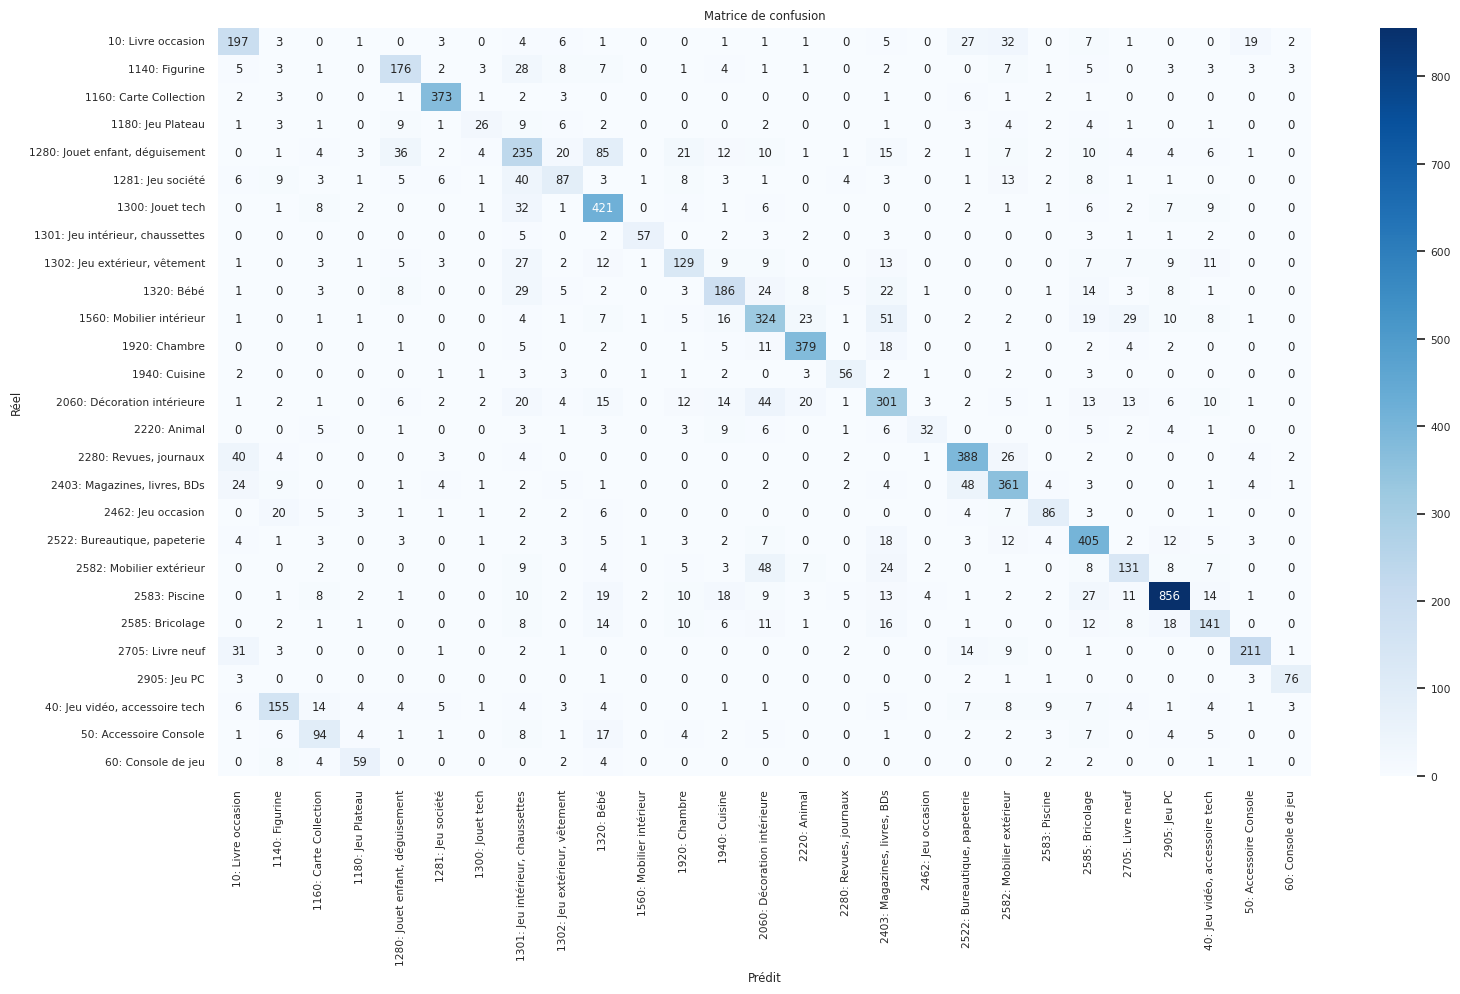

model_name                    VGG16 + CamemBERT — poids optimisés
dataset_resampled                                            True
test_size                                                  8492.0
image_model_name                                            VGG16
image_model_id                                              vgg16
text_model_name                                         CamemBERT
text_model_id                                           camembert
fusion_model            VotingClassifier(voting='soft') emulation
image_model_weight                                           0.75
text_model_weight                                            0.25
test_f1_score                                            0.038417
test_accuracy                                            0.038625
remarks               Meilleurs poids par grid search sur val set
Name: 531, dtype: object

In [18]:
model_id = 531
add_reporting_line(model_id, "VGG16 + CamemBERT — poids optimisés")

# Grid search sur les poids (sur val set pour éviter le data leakage)
print("Grid search sur Val set — VGG16 + CamemBERT...")
results_cam = []
y_val_str = df_val['prdtypecode'].astype("str").values

for w_img in np.arange(0.0, 1.05, 0.05).round(2):
    w_txt    = round(1.0 - w_img, 2)
    combined = (vgg16_val_probs * w_img) + (camembert_val_probs * w_txt)
    preds    = [classes_ordered[c] for c in np.argmax(combined, axis=1)]
    f1_val   = f1_score(y_val_str, preds, average="weighted")
    results_cam.append({'w_img': w_img, 'w_txt': w_txt, 'f1_val': round(f1_val, 4)})

df_grid_cam = pd.DataFrame(results_cam).sort_values('f1_val', ascending=False)
print("Top 5 combinaisons (VGG16 + CamemBERT) :")
print(df_grid_cam.head(5).to_string(index=False))

best_cam    = df_grid_cam.iloc[0]
img_weight  = best_cam['w_img']
text_weight = best_cam['w_txt']

# Application sur test
combined_test   = (vgg16_test_probs * img_weight) + (camembert_test_probs * text_weight)
test_pred_class = [classes_ordered[c] for c in np.argmax(combined_test, axis=1)]
y_test_str      = df_test['prdtypecode'].astype("str").values

f1  = f1_score(y_test_str, test_pred_class, average="weighted")
acc = accuracy_score(y_test_str, test_pred_class)

update_reporting_line(model_id, {
    "dataset_resampled": True, "test_size": len(y_test_str),
    "image_model_name": "VGG16", "image_model_id": "vgg16",
    "text_model_name": "CamemBERT", "text_model_id": "camembert",
    "fusion_model": "VotingClassifier(voting='soft') emulation",
    "image_model_weight": img_weight, "text_model_weight": text_weight,
    "test_f1_score": f1, "test_accuracy": acc,
    "remarks": f"Meilleurs poids par grid search sur val set"
})

print(f"\n🏆 Meilleurs poids : VGG16={img_weight} / CamemBERT={text_weight}")
print(f"   F1 Test  : {f1:.4f}")
print(f"   Accuracy : {acc:.4f}")
print(classification_report(y_test_str, test_pred_class))
cm = pd.crosstab(y_test_str, test_pred_class)
plot_confusion_matrix(np.array(cm), classes_ordered)

# Sauvegarde des prédictions finales pour Streamlit
np.save(OUTPUT_DIR / 'fusion_best_test_probs.npy', combined_test)
display(reporting_df.loc[model_id].T)

# CELLULE 11 — Comparaison finale de tous les modèles

model_id,511,512,521,531
model_name,VGG16 + TF-IDF/SVC — poids 0.5/0.5,VGG16 + TF-IDF/SVC — poids optimisés,Stacking LogisticRegression — VGG16 + TF-IDF/SVC,VGG16 + CamemBERT — poids optimisés
fusion_model,VotingClassifier(voting='soft') emulation,VotingClassifier(voting='soft') emulation,StackingClassifier(final_estimator=LogisticReg...,VotingClassifier(voting='soft') emulation
image_model_weight,0.5,0.0,0.5,0.75
text_model_weight,0.5,1.0,0.5,0.25
image_model_id,vgg16,vgg16,vgg16,vgg16
text_model_id,tfidf_svc,tfidf_svc,tfidf_svc,camembert
test_size,8491.0,8491.0,8491.0,8492.0
test_f1_score,0.338714,0.809392,0.379555,0.038417
test_accuracy,0.309386,0.81027,0.380756,0.038625


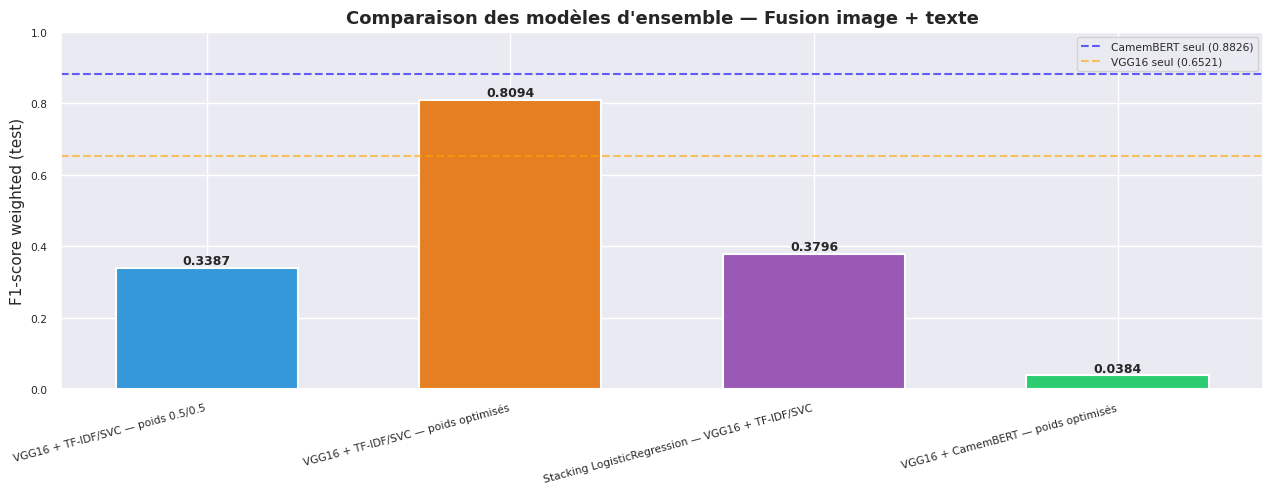


RÉSUMÉ — COMPARAISON GLOBALE TOUS MODÈLES
   TF-IDF + LinearSVC seul       : 0.8121
   VGG16 seul                    : 0.6521
   CamemBERT seul                : 0.8826
   VGG16 + TF-IDF/SVC — poids 0.5/0.5  : 0.3387
   VGG16 + TF-IDF/SVC — poids optimisés : 0.8094
   Stacking LogisticRegression — VGG16 + TF-IDF/SVC : 0.3796
   VGG16 + CamemBERT — poids optimisés : 0.0384


In [19]:
reporting_df = load_reporting_df()

ids_fusion = [i for i in [511, 512, 521, 531] if i in reporting_df.index]
cols = ["model_name", "fusion_model", "image_model_weight", "text_model_weight",
        "image_model_id", "text_model_id", "test_size",
        "test_f1_score", "test_accuracy"]

display(reporting_df.loc[ids_fusion, cols].T)

# Barplot comparaison
fig, ax = plt.subplots(figsize=(13, 5))

noms   = [reporting_df.at[i, 'model_name'] for i in ids_fusion]
f1s    = [reporting_df.at[i, 'test_f1_score'] for i in ids_fusion]
colors = ['#3498db', '#e67e22', '#9b59b6', '#2ecc71']

bars = ax.bar(noms, f1s, color=colors, edgecolor='white', linewidth=1.5, width=0.6)
ax.set_ylim(0, 1.0)
ax.set_ylabel("F1-score weighted (test)", fontsize=11)
ax.set_title("Comparaison des modèles d'ensemble — Fusion image + texte",
             fontsize=13, fontweight='bold')
ax.axhline(0.8826, color='blue',   linestyle='--', alpha=0.6,
           label='CamemBERT seul (0.8826)')
ax.axhline(0.6521, color='orange', linestyle='--', alpha=0.6,
           label='VGG16 seul (0.6521)')
ax.legend()

for bar, val in zip(bars, f1s):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{val:.4f}', ha='center', fontweight='bold', fontsize=9)

plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.savefig(WORK_DIR / 'fusion_ensemble_comparaison.png', dpi=150, bbox_inches='tight')
plt.show()

# Résumé
print("\n" + "=" * 60)
print("RÉSUMÉ — COMPARAISON GLOBALE TOUS MODÈLES")
print("=" * 60)
print(f"   TF-IDF + LinearSVC seul       : 0.8121")
print(f"   VGG16 seul                    : 0.6521")
print(f"   CamemBERT seul                : 0.8826")
for mid in ids_fusion:
    nom = reporting_df.at[mid, 'model_name']
    f1  = reporting_df.at[mid, 'test_f1_score']
    print(f"   {nom:<35} : {f1:.4f}")
print("=" * 60)